# 🇱🇰 LankaEnsemble Lab — Forecasting Colombo's Weather with Ensemble Learning
### Bagging · Boosting · Stacking · RF vs XGBoost · Hybrid ARIMA + RF · Hybrid RF + ANN — on ONE real Sri Lankan dataset

**Student:** B.N.V. Gunathilaka &nbsp;|&nbsp; **Index:** 224059P &nbsp;|&nbsp; **Faculty of IT, University of Moratuwa**
**Assignment:** Hands-on Project — Ensemble Learning Dashboard (10%)

---
## The story
Colombo's weather is never "just hot". Two monsoons (South-West, May–September; North-East, December–February) and two inter-monsoon seasons bring heavy rain, cloud and wind that change tomorrow's temperature in non-linear ways. Tomorrow's temperature matters for electricity demand (air-conditioning load), outdoor workers, farmers and events.

**Question:** *how well can ensemble learning forecast tomorrow's mean temperature in Colombo, and does a hybrid of a classical time-series model (ARIMA) and Random Forest beat both?*

| Part | What | Ensemble idea |
|---|---|---|
| A | Ensemble Arena — 13 models forecast tomorrow's temperature | **Bagging** vs **Boosting** vs **Stacking** |
| B | Is XGBoost really better than Random Forest? | **RF vs XGBoost**: time-series CV + significance test |
| C | ⭐ Hybrid **ARIMA + Random Forest** | ARIMA = linear/seasonal part, RF = non-linear weather effects |
| D | Hybrid **Random Forest + Neural Network** | Tabular regression on the same features |
| E | 💡 Innovation | Monsoon-season error analysis · "Tomorrow in Colombo" forecast with uncertainty, heat alert & rain what-if |

### Data
**One real dataset:** daily weather for Colombo (6.93°N, 79.86°E) from **1 Jan 2015 to 31 Oct 2026**, from the free **Open-Meteo historical archive (ERA5 reanalysis)** — mean / max / min temperature, rainfall, wind and solar radiation. It was downloaded through the Open-Meteo API and saved as `data/colombo_weather_daily_used.csv` so that every run gives identical results.

### 🤖 Generative AI declaration (required by the module)
Parts of the code in this notebook and the Streamlit dashboard UI were **generated with the help of Claude (Anthropic)**, then reviewed, run and checked by me. The analysis choices, interpretation and conclusions are my own responsibility.

## 0. Setup
Runs on **Google Colab** (Runtime → Run all) or any Jupyter. The copy in the GitHub repository was executed end-to-end automatically by **GitHub Actions** (`.github/workflows/run-notebook.yml`), so every output below is real.

In [1]:
%pip install -q xgboost lightgbm catboost statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import TimeSeriesSplit, KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor, VotingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
from statsmodels.tsa.arima.model import ARIMA
try:
    from catboost import CatBoostRegressor
    HAS_CATBOOST = True
except Exception:
    HAS_CATBOOST = False

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
DATA = Path("data"); DATA.mkdir(exist_ok=True)
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| catboost available:", HAS_CATBOOST)

xgboost 3.2.0 | lightgbm 4.7.0 | catboost available: True


## 1. Data — real Colombo daily weather (Open-Meteo / ERA5)

In [3]:
CSV = DATA / "colombo_weather_daily_used.csv"

def download_colombo_weather(start="2015-01-01", end="2026-10-31"):
    """How the dataset was collected (free Open-Meteo archive API, no key needed)."""
    import requests
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=6.9271&longitude=79.8612"
           f"&start_date={start}&end_date={end}"
           "&daily=temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,"
           "wind_speed_10m_max,shortwave_radiation_sum&timezone=Asia%2FColombo")
    r = requests.get(url, timeout=60); r.raise_for_status()
    return pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})

if CSV.exists():
    raw = pd.read_csv(CSV)
    print("Loaded the saved download:", CSV)
else:
    raw = download_colombo_weather(); raw.to_csv(CSV, index=False)
    print("Downloaded from Open-Meteo and saved to", CSV)
raw["date"] = pd.to_datetime(raw["date"])
wx = raw.set_index("date").asfreq("D").interpolate(limit_direction="both")
wx = wx.loc["2015-01-01":"2026-10-31"]
print(wx.shape, wx.index.min().date(), "→", wx.index.max().date(), "| missing values:", int(raw.isna().sum().sum()))
wx.describe().round(2)

Loaded the saved download: data/colombo_weather_daily_used.csv
(4322, 6) 2015-01-01 → 2026-10-31 | missing values: 0


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,shortwave_radiation_sum
count,4322.00,4322.00,4322.00,4322.00,4322.00,4322.00
mean,26.74,29.69,24.33,7.72,16.42,18.65
std,0.99,1.55,1.27,11.29,4.52,4.10
min,23.90,24.70,18.00,0.00,4.70,2.26
25%,26.00,28.60,23.50,1.10,13.10,16.19
50%,26.70,29.40,24.40,3.90,16.30,19.34
75%,27.40,30.60,25.20,10.20,19.40,21.79
max,30.10,35.50,27.90,231.40,41.90,26.15


### 1.1 EDA — Colombo's climate in four charts

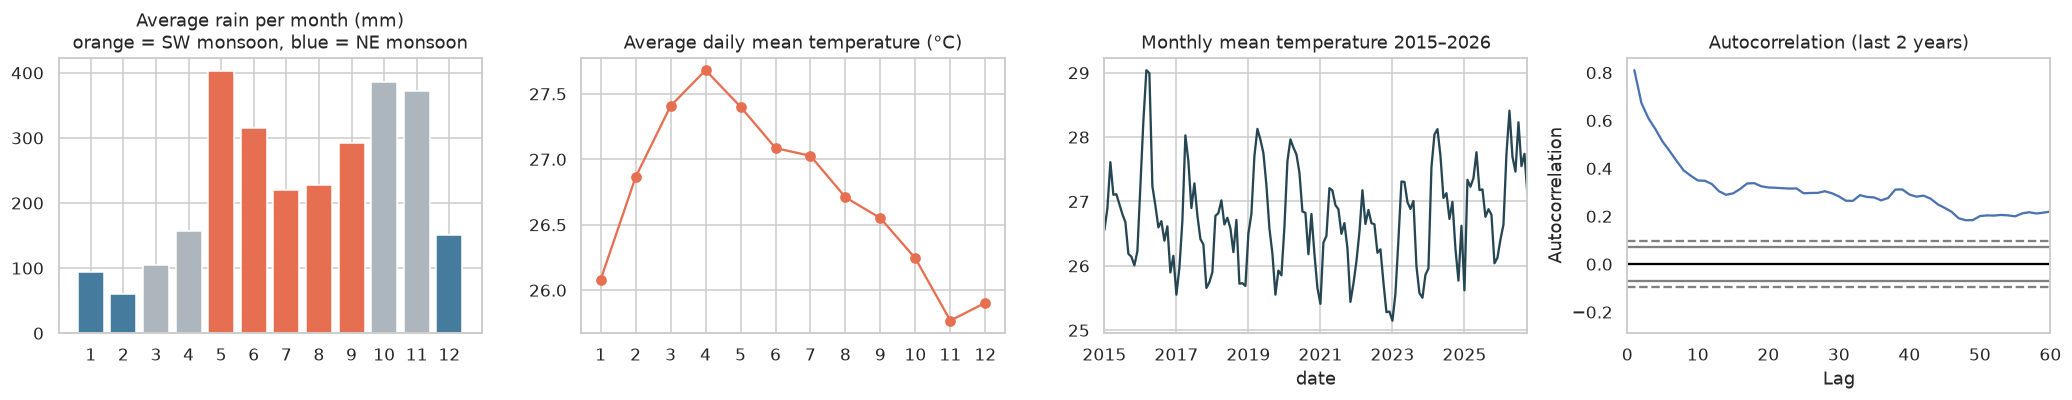

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
mon = wx.groupby(wx.index.month).agg(temp=("temperature_2m_mean", "mean"), rain=("precipitation_sum", "sum"))
mon["rain"] /= wx.index.year.nunique()
ax[0].bar(mon.index, mon.rain, color=["#e76f51" if m in (5, 6, 7, 8, 9) else ("#457b9d" if m in (12, 1, 2) else "#adb5bd") for m in mon.index])
ax[0].set_title("Average rain per month (mm)\norange = SW monsoon, blue = NE monsoon"); ax[0].set_xticks(range(1, 13))
ax[1].plot(mon.index, mon.temp, "o-", color="#e76f51"); ax[1].set_title("Average daily mean temperature (°C)"); ax[1].set_xticks(range(1, 13))
wx["temperature_2m_mean"].resample("MS").mean().plot(ax=ax[2], color="#264653"); ax[2].set_title("Monthly mean temperature 2015–2026")
pd.plotting.autocorrelation_plot(wx["temperature_2m_mean"].iloc[-730:], ax=ax[3]); ax[3].set_xlim(0, 60); ax[3].set_title("Autocorrelation (last 2 years)")
plt.tight_layout(); plt.show()

**Observations:** temperature is hottest in March–April and coolest in December–January; rainfall peaks in May (SW monsoon) and October–November (inter-monsoon). Today's temperature is strongly correlated with the next few days (autocorrelation), which is why lagged temperatures are powerful features — but rain, cloud (low solar radiation) and wind add **non-linear** effects that a purely linear model misses.

### 1.2 Features — everything known by the evening of the previous day
The target is **tomorrow's daily mean temperature**. All features use information up to the previous day only (no look-ahead). The last 365 days (Nov 2025 – Oct 2026) are the **test set**; everything before is training data.

In [5]:
def make_features(df):
    y = df["temperature_2m_mean"]
    f = pd.DataFrame(index=df.index)
    for L in [1, 2, 3, 4, 5, 6, 7, 14]:
        f[f"temp_lag{L}"] = y.shift(L)
    f["temp_roll7"] = y.shift(1).rolling(7).mean()
    f["temp_roll30"] = y.shift(1).rolling(30).mean()
    f["temp_last_year"] = y.shift(365)
    f["tmax_lag1"] = df["temperature_2m_max"].shift(1)
    f["tmin_lag1"] = df["temperature_2m_min"].shift(1)
    f["diurnal_range_lag1"] = f["tmax_lag1"] - f["tmin_lag1"]
    for L in [1, 2, 3]:
        f[f"rain_lag{L}"] = df["precipitation_sum"].shift(L)
        f[f"wind_lag{L}"] = df["wind_speed_10m_max"].shift(L)
        f[f"rad_lag{L}"] = df["shortwave_radiation_sum"].shift(L)
    f["rain_3d"] = df["precipitation_sum"].shift(1).rolling(3).sum()
    f["rain_7d"] = df["precipitation_sum"].shift(1).rolling(7).sum()
    doy = df.index.dayofyear
    f["doy_sin"], f["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    f["month"] = df.index.month
    f["sw_monsoon"] = df.index.month.isin([5, 6, 7, 8, 9]).astype(int)
    f["ne_monsoon"] = df.index.month.isin([12, 1, 2]).astype(int)
    return f

TEST_DAYS = 365
y_all = wx["temperature_2m_mean"]
X_all = make_features(wx)
ok = X_all.dropna().index
test_idx = wx.index[-TEST_DAYS:]
train_idx = ok[ok < test_idx[0]]
X_tr, y_tr = X_all.loc[train_idx], y_all.loc[train_idx]
X_te, y_te = X_all.loc[test_idx], y_all.loc[test_idx]
FEATS = list(X_all.columns)
print(f"Train {X_tr.shape} {train_idx.min().date()} → {train_idx.max().date()} | Test {X_te.shape} {test_idx.min().date()} → {test_idx.max().date()} | {len(FEATS)} features")

Train (3592, 30) 2016-01-01 → 2025-10-31 | Test (365, 30) 2025-11-01 → 2026-10-31 | 30 features


---
## 2. Part A — Ensemble Arena: Bagging vs Boosting vs Stacking

In [6]:
def models():
    base = [("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)),
            ("xgb", xgb.XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)),
            ("lgbm", lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)),
            ("ridge", make_pipeline(StandardScaler(), Ridge(alpha=1.0)))]
    m = {
        "Ridge regression (baseline)": ("Baseline", make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
        "Single Decision Tree": ("Baseline", DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=SEED)),
        # --- BAGGING (parallel trees, averaged -> lower variance)
        "Bagging (Decision Trees)": ("Bagging", BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=200, random_state=SEED, n_jobs=-1)),
        "Random Forest": ("Bagging", RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)),
        "Extra Trees": ("Bagging", ExtraTreesRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.7, random_state=SEED, n_jobs=-1)),
        # --- BOOSTING (sequential trees, each fixes the last -> lower bias)
        "AdaBoost": ("Boosting", AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=300, learning_rate=0.05, random_state=SEED)),
        "Gradient Boosting (sklearn)": ("Boosting", GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED)),
        "XGBoost": ("Boosting", xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)),
        "LightGBM": ("Boosting", lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)),
    }
    if HAS_CATBOOST:
        m["CatBoost"] = ("Boosting", CatBoostRegressor(iterations=600, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0))
    # --- STACKING / VOTING (different learners, combined)
    m["Stacking (RF+XGB+LGBM+Ridge → Ridge)"] = ("Stacking", StackingRegressor(base, final_estimator=RidgeCV(), cv=KFold(5), n_jobs=-1))
    m["Voting (average of RF+XGB+LGBM+Ridge)"] = ("Stacking", VotingRegressor(base, n_jobs=-1))
    return m

def reg_metrics(y, p):
    return {"MAE °C": mean_absolute_error(y, p), "RMSE °C": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}

naive = y_all.shift(1).loc[test_idx]
rows = [{"Model": "Naive (tomorrow = today)", "Family": "Baseline", **reg_metrics(y_te, naive), "Train s": 0.0}]
preds, fitted = {"Naive (tomorrow = today)": naive.values}, {}
for name, (fam, mdl) in models().items():
    t0 = time.time(); mdl.fit(X_tr, y_tr); secs = time.time() - t0
    p = mdl.predict(X_te)
    preds[name], fitted[name] = p, mdl
    rows.append({"Model": name, "Family": fam, **reg_metrics(y_te, p), "Train s": secs})
    print(f"{name:40s} RMSE={rows[-1]['RMSE °C']:.4f}  MAE={rows[-1]['MAE °C']:.4f}  ({secs:.1f}s)")
arena = pd.DataFrame(rows).sort_values("RMSE °C").reset_index(drop=True)
naive_rmse = arena.set_index("Model").loc["Naive (tomorrow = today)", "RMSE °C"]
arena["Skill vs naive %"] = 100 * (1 - arena["RMSE °C"] / naive_rmse)
arena.style.format({"MAE °C": "{:.4f}", "RMSE °C": "{:.4f}", "R²": "{:.3f}", "Train s": "{:.1f}", "Skill vs naive %": "{:+.1f}"}) \
     .background_gradient(subset=["RMSE °C"], cmap="Greens_r")

Ridge regression (baseline)              RMSE=0.5899  MAE=0.4577  (0.0s)
Single Decision Tree                     RMSE=0.6620  MAE=0.5167  (0.0s)


Bagging (Decision Trees)                 RMSE=0.5990  MAE=0.4779  (3.3s)


Random Forest                            RMSE=0.5935  MAE=0.4701  (2.2s)


Extra Trees                              RMSE=0.6003  MAE=0.4773  (1.0s)


AdaBoost                                 RMSE=0.6285  MAE=0.5048  (4.9s)


Gradient Boosting (sklearn)              RMSE=0.6001  MAE=0.4800  (5.6s)


... (2 outputs left out)

CatBoost                                 RMSE=0.5986  MAE=0.4793  (0.7s)


Stacking (RF+XGB+LGBM+Ridge → Ridge)     RMSE=0.5827  MAE=0.4551  (10.5s)


Voting (average of RF+XGB+LGBM+Ridge)    RMSE=0.5865  MAE=0.4643  (1.7s)


,Model,Family,MAE °C,RMSE °C,R²,Train s,Skill vs naive %
0,Stacking (RF+XGB+LGBM+Ridge → Ridge),Stacking,0.4551,0.5827,0.711,10.5,+8.6
1,Voting (average of RF+XGB+LGBM+Ridge),Stacking,0.4643,0.5865,0.707,1.7,+8.1
2,Ridge regression (baseline),Baseline,0.4577,0.5899,0.704,0.0,+7.5
3,Random Forest,Bagging,0.4701,0.5935,0.700,2.2,+6.9
4,LightGBM,Boosting,0.4748,0.5963,0.697,0.3,+6.5
5,CatBoost,Boosting,0.4793,0.5986,0.695,0.7,+6.1
6,Bagging (Decision Trees),Bagging,0.4779,0.5990,0.694,3.3,+6.1
7,Gradient Boosting (sklearn),Boosting,0.4800,0.6001,0.693,5.6,+5.9
8,Extra Trees,Bagging,0.4773,0.6003,0.693,1.0,+5.9
9,XGBoost,Boosting,0.4935,0.6126,0.680,0.4,+4.0


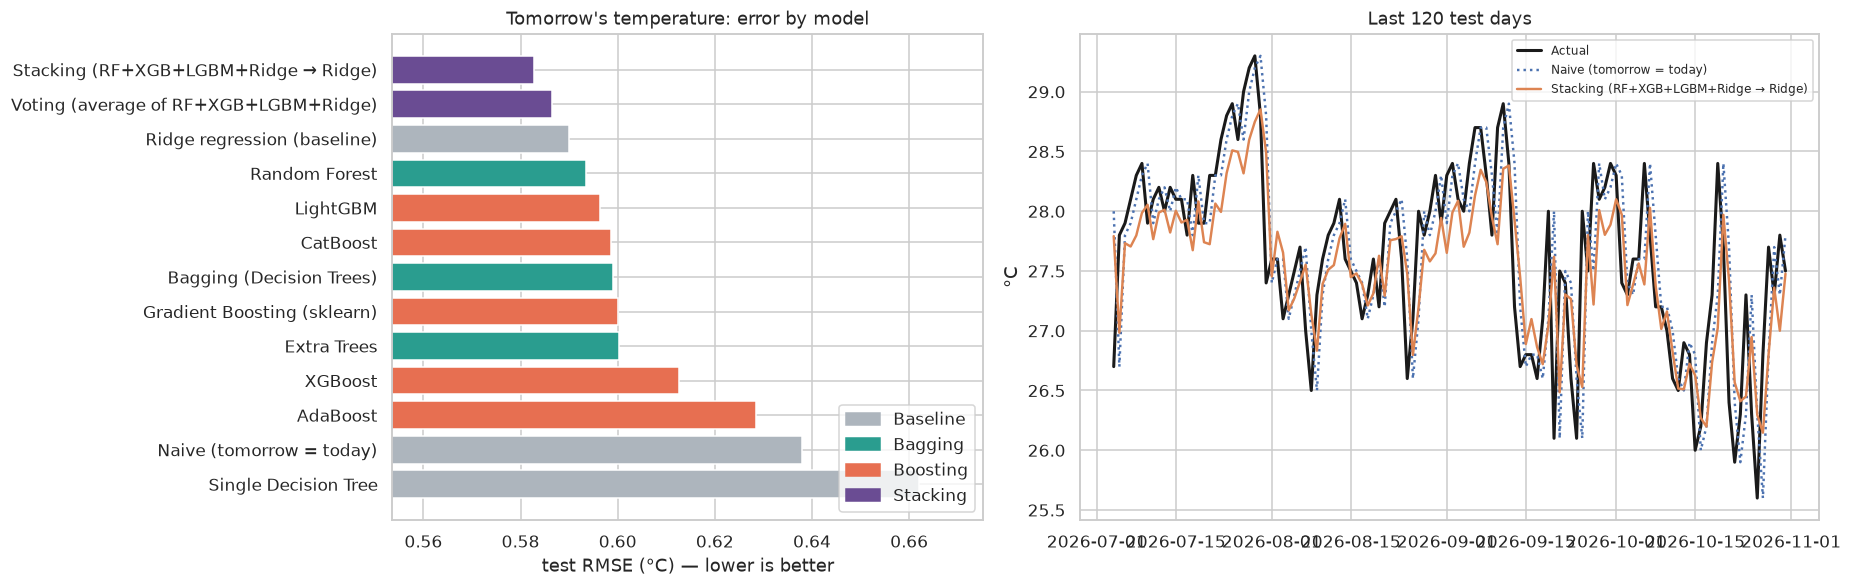

             min    mean
Family                  
Stacking  0.5827  0.5846
Baseline  0.5899  0.6299
Bagging   0.5935  0.5976
Boosting  0.5963  0.6072


In [7]:
from matplotlib.patches import Patch
fam_colors = {"Baseline": "#adb5bd", "Bagging": "#2a9d8f", "Boosting": "#e76f51", "Stacking": "#6a4c93"}
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
a = arena.sort_values("RMSE °C", ascending=False)
ax[0].barh(a.Model, a["RMSE °C"], color=[fam_colors[f] for f in a.Family])
ax[0].set_xlim(a["RMSE °C"].min() * 0.95, a["RMSE °C"].max() * 1.02); ax[0].set_xlabel("test RMSE (°C) — lower is better")
ax[0].set_title("Tomorrow's temperature: error by model")
ax[0].legend(handles=[Patch(color=c, label=f) for f, c in fam_colors.items()], loc="lower right")
last = test_idx[-120:]
ax[1].plot(last, y_te.loc[last], "k-", lw=2, label="Actual")
best_name = arena.iloc[0].Model
for nm, st in [("Naive (tomorrow = today)", ":"), (best_name, "-")]:
    ax[1].plot(last, pd.Series(preds[nm], index=test_idx).loc[last], st, lw=1.6, label=nm)
ax[1].set_title("Last 120 test days"); ax[1].set_ylabel("°C"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(arena.groupby("Family")["RMSE °C"].agg(["min", "mean"]).sort_values("min").round(4))

### Interpreting Part A
* **Bagging vs a single tree:** one deep tree memorises noise (high variance). Bagging and Random Forest average hundreds of trees trained on bootstrap samples, which cancels much of that variance — the jump from the single tree to RF/Extra Trees shows it directly.
* **Boosting:** shallow trees are added one after another, each correcting the remaining error (bias). With a small learning rate this captures smooth seasonal structure plus thresholds such as "heavy rain yesterday → cooler today".
* **Linear models are strong here.** Tomorrow's temperature is mostly a linear function of the last few days, so Ridge regression is a tough baseline; the ensembles win by adding the *non-linear* weather effects. The gaps between the best models are small (hundredths of a degree), which is why Part B tests whether differences are real.
* **Stacking / voting** combine models whose errors are not perfectly correlated (linear Ridge + bagged RF + boosted XGB/LGBM), usually giving the most robust result at a higher training cost.
* **Skill vs naive** shows how much each model improves on "tomorrow = today".

In [8]:
best = arena.iloc[0]
tree_rmse = arena.set_index("Model").loc["Single Decision Tree", "RMSE °C"]
rf_rmse = arena.set_index("Model").loc["Random Forest", "RMSE °C"]
print(f"Best model: {best.Model} ({best.Family}) — RMSE {best['RMSE °C']:.4f} °C, skill vs naive {best['Skill vs naive %']:+.1f}%")
print(f"Bagging effect: single tree RMSE {tree_rmse:.4f} → Random Forest {rf_rmse:.4f} ({100 * (1 - rf_rmse / tree_rmse):.1f}% lower error)")

Best model: Stacking (RF+XGB+LGBM+Ridge → Ridge) (Stacking) — RMSE 0.5827 °C, skill vs naive +8.6%
Bagging effect: single tree RMSE 0.6620 → Random Forest 0.5935 (10.3% lower error)


---
## 3. Part B — Random Forest vs XGBoost
Time-series cross-validation: 6 expanding-window folds, each testing on the **next unseen year** of the training period. The difference is tested with the **Nadeau–Bengio corrected t-test** (fold scores are correlated because training sets overlap).

In [9]:
rf_b = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
xgb_b = xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
tscv = TimeSeriesSplit(n_splits=6, test_size=365)
res = {"RF": [], "XGB": []}; sizes = []
for tr, va in tscv.split(X_tr):
    sizes.append((len(tr), len(va)))
    for key, mdl in [("RF", rf_b), ("XGB", xgb_b)]:
        mdl.fit(X_tr.iloc[tr], y_tr.iloc[tr])
        res[key].append(np.sqrt(mean_squared_error(y_tr.iloc[va], mdl.predict(X_tr.iloc[va]))))
d = np.array(res["XGB"]) - np.array(res["RF"]); k = len(d)
n_tr, n_te = np.mean([s[0] for s in sizes]), np.mean([s[1] for s in sizes])
t_stat = d.mean() / np.sqrt(d.var(ddof=1) * (1 / k + n_te / n_tr))
p_val = 2 * stats.t.sf(abs(t_stat), k - 1)
cmp = pd.DataFrame({k_: {"Mean CV RMSE °C": np.mean(v), "Std": np.std(v), "Folds won": int(np.sum(np.array(v) <= np.array(res["RF" if k_ == "XGB" else "XGB"])))} for k_, v in res.items()}).T
display(cmp.round(4))
print(f"XGB − RF mean RMSE difference = {d.mean():+.4f} °C | corrected t = {t_stat:.2f} | p = {p_val:.3f} →",
      "SIGNIFICANT at 5%" if p_val < 0.05 else "NOT significant at 5%")

,Mean CV RMSE °C,Std,Folds won
RF,0.4998,0.0567,4.0
XGB,0.5029,0.0552,2.0


XGB − RF mean RMSE difference = +0.0031 °C | corrected t = 0.64 | p = 0.552 → NOT significant at 5%


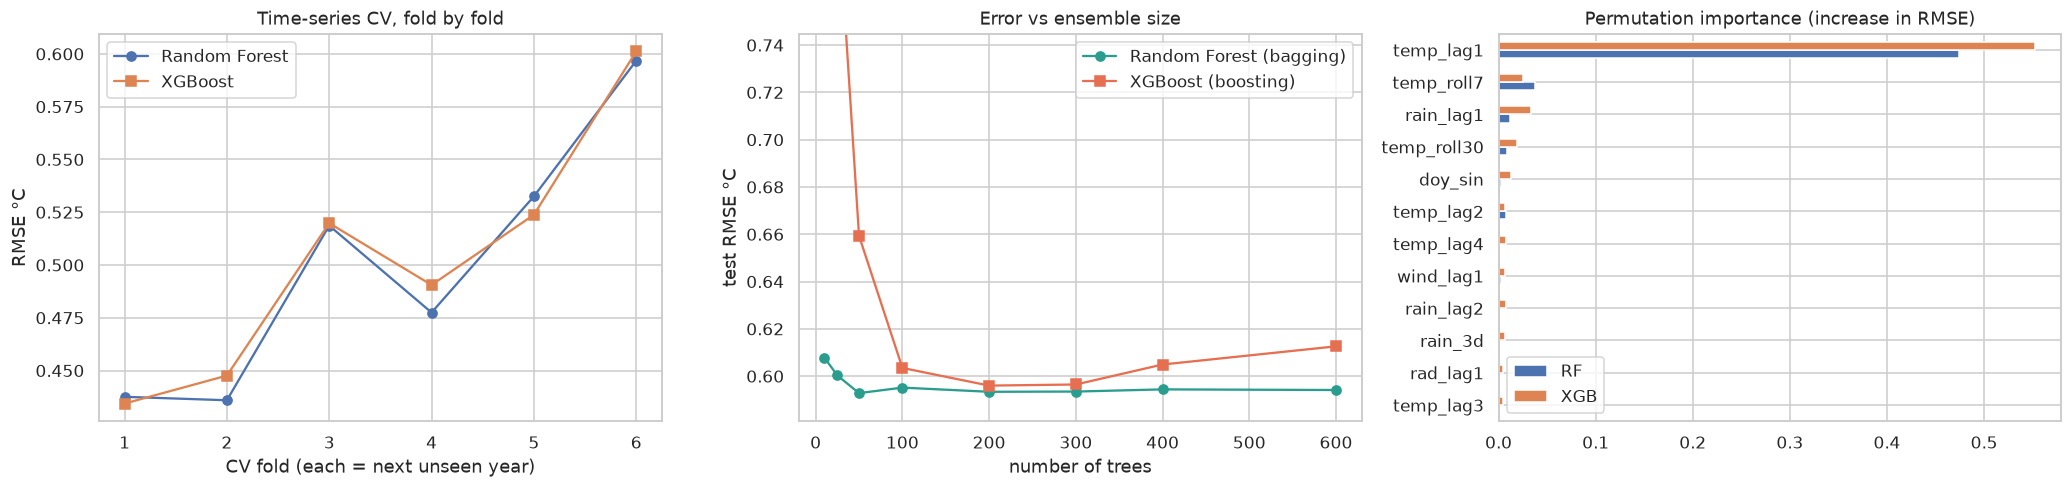

In [10]:
Ns = [10, 25, 50, 100, 200, 300, 400, 600]
rf_w = RandomForestRegressor(min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1, warm_start=True)
rf_curve = []
for n in Ns:
    rf_w.set_params(n_estimators=n); rf_w.fit(X_tr, y_tr)
    rf_curve.append(np.sqrt(mean_squared_error(y_te, rf_w.predict(X_te))))
xg_full = fitted["XGBoost"]
xgb_curve = [np.sqrt(mean_squared_error(y_te, xg_full.predict(X_te, iteration_range=(0, n)))) for n in Ns]
pi = {}
for key, name in [("RF", "Random Forest"), ("XGB", "XGBoost")]:
    r = permutation_importance(fitted[name], X_te, y_te, scoring="neg_root_mean_squared_error", n_repeats=5, random_state=SEED, n_jobs=-1)
    pi[key] = pd.Series(r.importances_mean, index=FEATS)
imp = pd.DataFrame(pi); imp = imp.loc[imp.sum(axis=1).sort_values(ascending=False).index[:12]]
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
ax[0].plot(range(1, k + 1), res["RF"], "o-", label="Random Forest"); ax[0].plot(range(1, k + 1), res["XGB"], "s-", label="XGBoost")
ax[0].set_xlabel("CV fold (each = next unseen year)"); ax[0].set_ylabel("RMSE °C"); ax[0].set_title("Time-series CV, fold by fold"); ax[0].legend()
ax[1].plot(Ns, rf_curve, "o-", color="#2a9d8f", label="Random Forest (bagging)"); ax[1].plot(Ns, xgb_curve, "s-", color="#e76f51", label="XGBoost (boosting)")
ax[1].set_ylim(min(rf_curve + xgb_curve) * 0.98, min(max(rf_curve + xgb_curve), np.percentile(xgb_curve + rf_curve, 85) * 1.15))
ax[1].set_xlabel("number of trees"); ax[1].set_ylabel("test RMSE °C"); ax[1].set_title("Error vs ensemble size"); ax[1].legend()
imp.iloc[::-1].plot.barh(ax=ax[2]); ax[2].set_title("Permutation importance (increase in RMSE)")
plt.tight_layout(); plt.show()

### Interpreting RF vs XGBoost
* **Ensemble size:** Random Forest improves quickly and then **plateaus** — extra trees only average more and never over-fit. XGBoost starts very poorly (with few trees and a 0.03 learning rate it has barely moved from the starting guess, i.e. high bias) and improves steadily as each tree corrects the remaining error; with too many trees boosting can start fitting noise, which is why it needs early stopping or a tuned number of trees.
* **Which one wins** on *this* data is decided by the time-series CV and the corrected t-test above, not by one lucky split.
* **Feature importance:** both models rely mostly on **yesterday's temperature**, the recent averages and **yesterday's solar radiation / rain** (cloudy, rainy days are followed by cooler days). When two very different algorithms agree on the drivers, the explanation is more trustworthy.

---
## 4. Part C — ⭐ Hybrid ARIMA + Random Forest (Zhang, 2003)
A time series = **linear autocorrelated part** + **non-linear part**.
1. **ARIMA** (with Fourier terms for the yearly cycle) models the linear part → forecast $\hat L_t$.
2. **Random Forest** learns ARIMA's error $e_t$ from lagged errors and lagged weather (rain, wind, radiation, monsoon flags).
3. Final forecast $\hat y_t = \hat L_t + \hat e_t$ — still using information up to day $t-1$ only.

In [11]:
doy = wx.index.dayofyear.values
fourier = pd.DataFrame({"s1": np.sin(2 * np.pi * doy / 365.25), "c1": np.cos(2 * np.pi * doy / 365.25),
                        "s2": np.sin(4 * np.pi * doy / 365.25), "c2": np.cos(4 * np.pi * doy / 365.25),
                        "trend": np.arange(len(wx)) / 3652.5}, index=wx.index)
y_tr_ts, y_te_ts = y_all.iloc[:-TEST_DAYS], y_all.iloc[-TEST_DAYS:]
F_tr, F_te = fourier.iloc[:-TEST_DAYS], fourier.iloc[-TEST_DAYS:]
grid = []
for p_ in [1, 2, 3]:
    for q_ in [0, 1, 2]:
        try:
            grid.append(((p_, 0, q_), ARIMA(y_tr_ts, exog=F_tr, order=(p_, 0, q_), trend="c").fit().aic))
        except Exception:
            pass
grid = sorted(grid, key=lambda z: z[1]); ORDER = grid[0][0]
print("Top orders by AIC:", [(o, round(a_, 1)) for o, a_ in grid[:4]], "→ chosen", ORDER)
arima_res = ARIMA(y_tr_ts, exog=F_tr, order=ORDER, trend="c").fit()
arima_full = arima_res.append(y_te_ts, exog=F_te, refit=False)     # parameters fixed from training: no leakage
arima_fc = arima_full.fittedvalues                                  # one-step-ahead forecasts for every day
resid = y_all - arima_fc

def resid_features(df, resid, y):
    f = pd.DataFrame(index=df.index)
    for L in range(1, 8):
        f[f"resid_lag{L}"] = resid.shift(L)
    for L in (1, 2, 3):
        f[f"rain_lag{L}"] = df["precipitation_sum"].shift(L)
        f[f"wind_lag{L}"] = df["wind_speed_10m_max"].shift(L)
        f[f"rad_lag{L}"] = df["shortwave_radiation_sum"].shift(L)
        f[f"temp_lag{L}"] = y.shift(L)
    f["rain_3d_sum"] = df["precipitation_sum"].shift(1).rolling(3).sum()
    f["rain_7d_sum"] = df["precipitation_sum"].shift(1).rolling(7).sum()
    f["diurnal_range_lag1"] = (df["temperature_2m_max"] - df["temperature_2m_min"]).shift(1)
    f["doy_sin"], f["doy_cos"] = np.sin(2 * np.pi * df.index.dayofyear / 365.25), np.cos(2 * np.pi * df.index.dayofyear / 365.25)
    f["month"] = df.index.month
    f["sw_monsoon"] = df.index.month.isin([5, 6, 7, 8, 9]).astype(int)
    f["ne_monsoon"] = df.index.month.isin([12, 1, 2]).astype(int)
    return f

RF_ = resid_features(wx, resid, y_all)
valid = RF_.dropna().index
h_tr = valid[valid < test_idx[0]][30:]                              # skip the ARIMA burn-in
rf_res = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
rf_res.fit(RF_.loc[h_tr], resid.loc[h_tr])
hybrid = arima_fc.loc[test_idx] + rf_res.predict(RF_.loc[test_idx])
hyb_tab = pd.DataFrame({k_: reg_metrics(y_te, v) for k_, v in {
    "Naive (tomorrow = today)": naive, f"ARIMA{ORDER} + Fourier": arima_fc.loc[test_idx],
    "Random Forest (direct, Part A)": preds["Random Forest"], "XGBoost (Part A)": preds["XGBoost"],
    "⭐ Hybrid ARIMA + RF": hybrid}.items()}).T.sort_values("RMSE °C")
display(hyb_tab.style.format("{:.4f}").background_gradient(subset=["RMSE °C"], cmap="Greens_r"))
gain = 100 * (1 - hyb_tab.loc["⭐ Hybrid ARIMA + RF", "RMSE °C"] / hyb_tab.loc[f"ARIMA{ORDER} + Fourier", "RMSE °C"])
print(f"Hybrid vs ARIMA alone: RMSE {gain:+.1f}% better (positive = hybrid better)")

Top orders by AIC: [((2, 0, 2), np.float64(5419.0)), ((3, 0, 1), np.float64(5420.9)), ((3, 0, 2), np.float64(5425.6)), ((1, 0, 2), np.float64(5466.5))] → chosen (2, 0, 2)


,MAE °C,RMSE °C,R²
⭐ Hybrid ARIMA + RF,0.4506,0.5721,0.7212
"Random Forest (direct, Part A)",0.4701,0.5935,0.6999
"ARIMA(2, 0, 2) + Fourier",0.4652,0.5953,0.6981
XGBoost (Part A),0.4935,0.6126,0.6804
Naive (tomorrow = today),0.4893,0.6378,0.6535


Hybrid vs ARIMA alone: RMSE +3.9% better (positive = hybrid better)


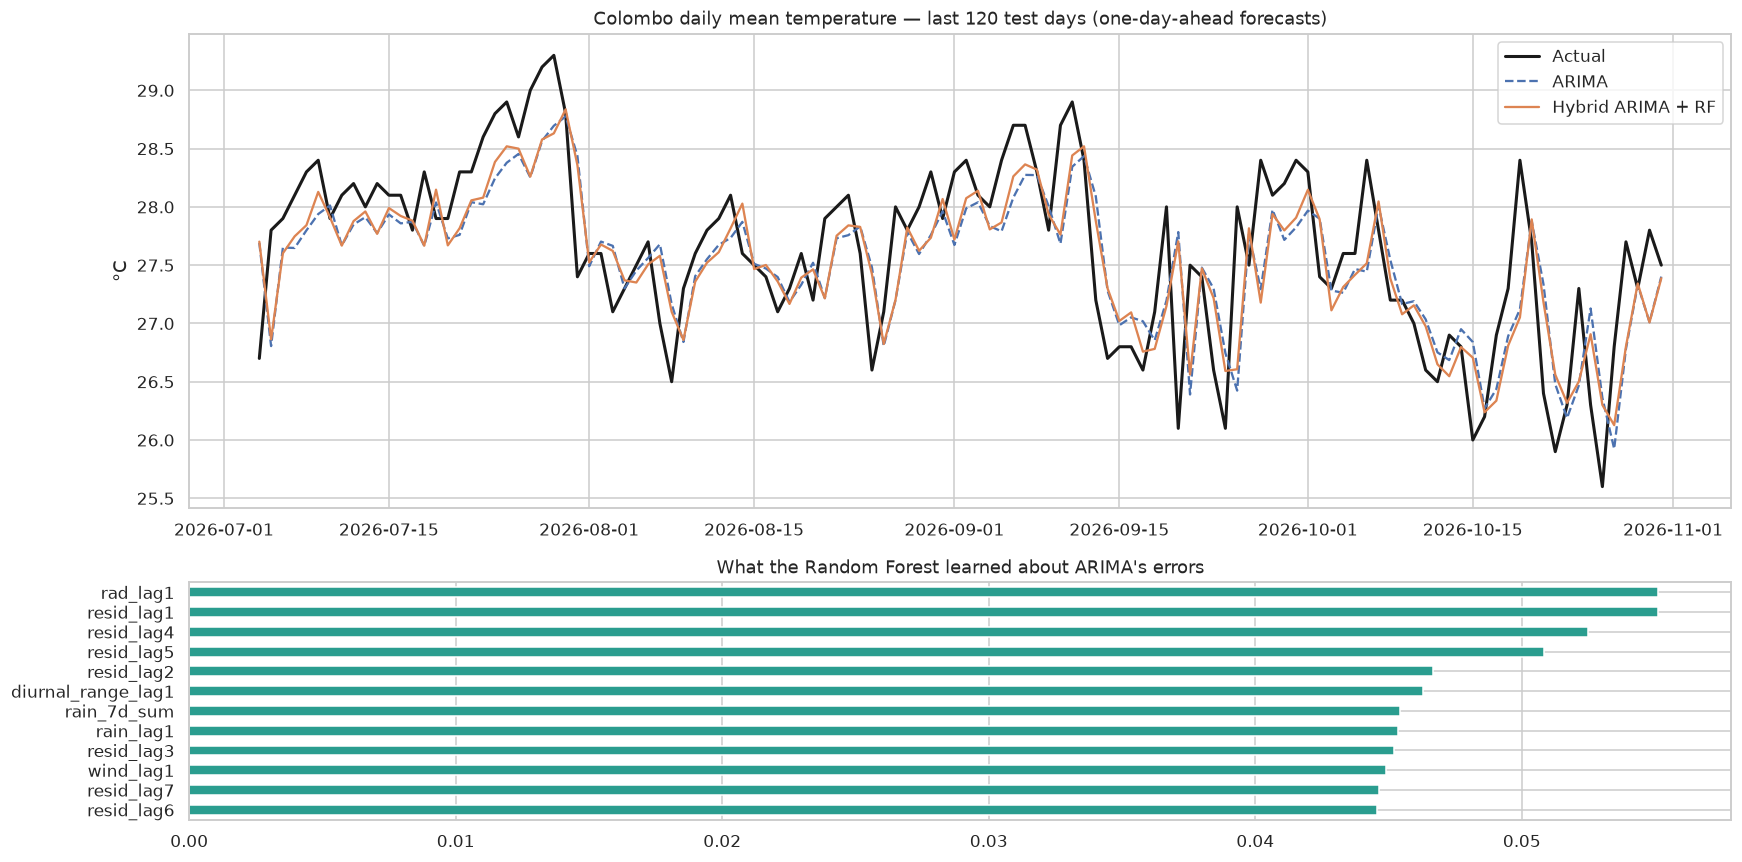

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(16, 8), gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(last, y_te.loc[last], "k-", lw=2, label="Actual")
ax[0].plot(last, arima_fc.loc[last], "--", label="ARIMA")
ax[0].plot(last, hybrid.loc[last], "-", label="Hybrid ARIMA + RF")
ax[0].set_title("Colombo daily mean temperature — last 120 test days (one-day-ahead forecasts)"); ax[0].set_ylabel("°C"); ax[0].legend()
imp_h = pd.Series(rf_res.feature_importances_, index=RF_.columns).sort_values(ascending=False)[:12]
imp_h.iloc[::-1].plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].set_title("What the Random Forest learned about ARIMA's errors")
plt.tight_layout(); plt.show()

### Interpreting ARIMA + RF
* **ARIMA** captures the linear, autocorrelated part: tomorrow resembles today, plus the yearly cycle and slow warming trend. That alone already beats "tomorrow = today".
* **ARIMA cannot see the weather:** a heavy-rain day, a cloudy low-radiation spell or the strong SW-monsoon winds push tomorrow's temperature in ways a linear model on temperature alone cannot represent. The Random Forest trained on ARIMA's residuals learns exactly these effects — yesterday's **solar radiation**, recent **residuals** and **rain** are its top features.
* The hybrid combines the strengths: ARIMA extrapolates trend and season (trees cannot), the forest adds non-linear weather corrections (ARIMA cannot).

---
## 5. Part D — Hybrid Random Forest + Neural Network (tabular regression)
Same tabular features as Part A. Three ways to combine RF with a neural network (MLP):
1. **Weighted blend** — weight chosen on out-of-fold training predictions; 2. **Residual hybrid** — the ANN learns what the RF missed; 3. **Stacking** — Ridge meta-learner.

Note: the network's target is **standardised** (`TransformedTargetRegressor`). Without it the MLP spends its training just learning the ~27 °C offset and its error is about 40% worse.

In [13]:
sc = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = sc.transform(X_tr), sc.transform(X_te)
rf_v = RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)
def ann(hidden=(64, 32)):
    # the target (~27 °C) is standardised; otherwise the network spends its training learning the offset
    return TransformedTargetRegressor(MLPRegressor(hidden_layer_sizes=hidden, alpha=1e-2, learning_rate_init=1e-3, max_iter=800,
                                                   early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
                                                   random_state=SEED), transformer=StandardScaler())
ann_v = ann()
kf = KFold(5)                                                   # ordered folds (no shuffling)
oof_rf = cross_val_predict(rf_v, X_tr, y_tr, cv=kf, n_jobs=-1)
oof_ann = cross_val_predict(ann_v, Xs_tr, y_tr, cv=kf)
rf_v.fit(X_tr, y_tr); ann_v.fit(Xs_tr, y_tr)
p_rf, p_ann = rf_v.predict(X_te), ann_v.predict(Xs_te)
ws = np.linspace(0, 1, 101)
w_best = ws[np.argmin([mean_squared_error(y_tr, w * oof_rf + (1 - w) * oof_ann) for w in ws])]
p_blend = w_best * p_rf + (1 - w_best) * p_ann
res_ann = ann((32,))
res_ann.fit(np.column_stack([Xs_tr, oof_rf]), y_tr - oof_rf)
p_resid = p_rf + res_ann.predict(np.column_stack([Xs_te, p_rf]))
stack_v = StackingRegressor([("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=-1)),
                             ("ann", make_pipeline(StandardScaler(), ann()))],
                            final_estimator=RidgeCV(), cv=KFold(5), n_jobs=-1).fit(X_tr, y_tr)
p_stack = stack_v.predict(X_te)
ann_tab = pd.DataFrame({k_: reg_metrics(y_te, v) for k_, v in {
    "Random Forest": p_rf, "ANN (MLP)": p_ann, f"Hybrid 1: Blend (w_RF={w_best:.2f})": p_blend,
    "Hybrid 2: RF + ANN residual": p_resid, "Hybrid 3: Stacking RF+ANN → Ridge": p_stack}.items()}).T.sort_values("RMSE °C")
display(ann_tab.style.format("{:.4f}").background_gradient(subset=["RMSE °C"], cmap="Greens_r"))
print("Correlation of RF and ANN test errors:", np.corrcoef(y_te - p_rf, y_te - p_ann)[0, 1].round(3))

,MAE °C,RMSE °C,R²
Hybrid 3: Stacking RF+ANN → Ridge,0.4595,0.5817,0.7117
Hybrid 2: RF + ANN residual,0.4631,0.5844,0.7091
Hybrid 1: Blend (w_RF=0.74),0.4656,0.5867,0.7068
Random Forest,0.4701,0.5935,0.6999
ANN (MLP),0.4767,0.5969,0.6965


Correlation of RF and ANN test errors: 0.934


### Interpreting RF + ANN
* The **RF** handles thresholds (heavy rain, monsoon flags) but predicts in steps and cannot extrapolate beyond temperatures seen in training; the **ANN** learns smooth relationships (temperature is close to linear in its lags) but is sensitive to scaling and training noise.
* Combining them helps only as much as their errors differ — the error correlation printed above tells how much room there is. Weighted blending and stacking are the safest ways to combine two similar models; a residual ANN gains little when the RF's out-of-fold errors are mostly noise.

---
## 6. 💡 Innovation
### 6.1 Which model wins in which monsoon season?
Colombo has four seasons. A single RMSE hides *when* each model fails. Here the test-year errors are split by season.

In [14]:
season = pd.Series(np.select([test_idx.month.isin([12, 1, 2]), test_idx.month.isin([3, 4]), test_idx.month.isin([5, 6, 7, 8, 9])],
                             ["NE monsoon (Dec–Feb)", "1st inter-monsoon (Mar–Apr)", "SW monsoon (May–Sep)"], "2nd inter-monsoon (Oct–Nov)"), index=test_idx)
cand = {"Naive": naive.values, f"ARIMA{ORDER}": arima_fc.loc[test_idx].values, "Ridge": preds["Ridge regression (baseline)"],
        "Random Forest": preds["Random Forest"], "XGBoost": preds["XGBoost"], "Hybrid ARIMA+RF": hybrid.values}
seas = pd.DataFrame({nm: [np.sqrt(np.mean((y_te.values[season.values == s] - p[season.values == s]) ** 2)) for s in season.unique()]
                     for nm, p in cand.items()}, index=season.unique())
display(seas.style.format("{:.3f}").highlight_min(axis=1, color="#c7f0d8"))
print("Best model per season:", seas.idxmin(axis=1).to_dict())

,Naive,"ARIMA(2, 0, 2)",Ridge,Random Forest,XGBoost,Hybrid ARIMA+RF
2nd inter-monsoon (Oct–Nov),0.662,0.619,0.636,0.630,0.635,0.592
NE monsoon (Dec–Feb),0.664,0.614,0.598,0.592,0.606,0.594
1st inter-monsoon (Mar–Apr),0.618,0.584,0.577,0.587,0.577,0.568
SW monsoon (May–Sep),0.620,0.579,0.571,0.582,0.622,0.552


Best model per season: {'2nd inter-monsoon (Oct–Nov)': 'Hybrid ARIMA+RF', 'NE monsoon (Dec–Feb)': 'Random Forest', '1st inter-monsoon (Mar–Apr)': 'Hybrid ARIMA+RF', 'SW monsoon (May–Sep)': 'Hybrid ARIMA+RF'}


### 6.2 "Tomorrow in Colombo" — forecast with uncertainty and a heat alert
A single number is not enough for planning. Using the hybrid's errors over the whole test year, I turn the forecast into an **80% interval** (empirical quantiles of past errors), and a **heat alert** when even the lower end of the interval is above 28.5 °C (a hot day for Colombo). The dashboard adds a **rain what-if**: change today's rain/cloud and see tomorrow's forecast move.

In [15]:
err = (y_te - hybrid).values
q_lo, q_hi = np.quantile(err, [0.10, 0.90])
coverage = np.mean((y_te.values >= hybrid.values + q_lo) & (y_te.values <= hybrid.values + q_hi))
nxt = wx.index[-1] + pd.Timedelta(days=1)
wx2 = pd.concat([wx, pd.DataFrame(index=[nxt], columns=wx.columns, dtype=float)])
y2 = pd.concat([y_all, pd.Series([np.nan], index=[nxt])]); r2 = pd.concat([resid, pd.Series([np.nan], index=[nxt])])
f_next = resid_features(wx2, r2, y2).loc[[nxt]]
fd = np.arange(len(wx), len(wx) + 1)
F_next = pd.DataFrame({"s1": np.sin(2 * np.pi * nxt.dayofyear / 365.25), "c1": np.cos(2 * np.pi * nxt.dayofyear / 365.25),
                       "s2": np.sin(4 * np.pi * nxt.dayofyear / 365.25), "c2": np.cos(4 * np.pi * nxt.dayofyear / 365.25),
                       "trend": fd / 3652.5}, index=[nxt])
a_next = float(np.asarray(arima_full.forecast(1, exog=F_next))[0])
h_next = a_next + float(rf_res.predict(f_next)[0])
print(f"Forecast for {nxt.date()}: {h_next:.1f} °C   80% interval: {h_next + q_lo:.1f} – {h_next + q_hi:.1f} °C "
      f"(interval covered {100 * coverage:.0f}% of test days)   heat alert: {'YES' if h_next + q_lo > 28.5 else 'no'}")

Forecast for 2026-11-01: 27.2 °C   80% interval: 26.5 – 27.9 °C (interval covered 80% of test days)   heat alert: no


---
## 7. Research — Random Forest vs other ensemble methods
| | **Random Forest** (bagging) | **XGBoost** | **LightGBM** | **CatBoost** |
|---|---|---|---|---|
| How trees are built | Independent, deep, on bootstrap samples + random features | Sequential, depth-wise, 2nd-order gradients + regularisation | Sequential, **leaf-wise**, histogram binning, GOSS | Sequential, **symmetric (oblivious)** trees, ordered boosting |
| Mainly reduces | Variance | Bias | Bias | Bias (+ less target leakage) |
| Tuning needed | Very little | Moderate (lr, depth, trees) | Moderate (num_leaves can over-fit) | Little — good defaults |
| Categoricals | Need encoding | Need encoding / partial native | Native | **Native, best-in-class** |
| Speed | Parallel trees | Fast (hist) | **Fastest** on big data | Slower to train, fast to predict |
| Over-fitting risk | Low (more trees never hurts) | Higher with many trees / high lr | Higher on small data | Lower (ordered boosting) |

**Time series:** tree ensembles **cannot extrapolate** a trend or a never-seen temperature — they only average values seen in training. That is the main reason the **ARIMA + RF hybrid** works: ARIMA handles trend and season, the forest handles non-linear weather effects.

**Tabular vs image/text data**
* **Tabular (this project):** tree ensembles are still state-of-the-art for medium-sized tabular data — mixed feature types, thresholds and interactions with little preprocessing; gradient boosting usually edges out RF.
* **Images / text:** the signal lives in spatial or sequential structure (pixels → shapes, words → meaning). Trees split on one raw feature at a time and cannot learn translation-invariant filters or embeddings, so **CNNs / Transformers dominate**; ensembles are used on top of their embeddings or to average several networks.

## 8. Summary of results (auto-generated from this run)

In [16]:
summary = {
    "Data": f"Real Colombo daily weather (Open-Meteo ERA5), {wx.index.min().date()} → {wx.index.max().date()}, test = last 365 days",
    "Part A best model": f"{arena.iloc[0].Model} ({arena.iloc[0].Family}) — RMSE {arena.iloc[0]['RMSE °C']:.3f} °C, skill vs naive {arena.iloc[0]['Skill vs naive %']:+.1f}%",
    "Part A bagging effect": f"single tree {tree_rmse:.3f} → Random Forest {rf_rmse:.3f} °C",
    "Part B RF vs XGB": f"CV RMSE RF {np.mean(res['RF']):.3f} vs XGB {np.mean(res['XGB']):.3f} °C; p = {p_val:.3f}",
    "Part C hybrid ARIMA+RF": f"RMSE {hyb_tab.loc['⭐ Hybrid ARIMA + RF', 'RMSE °C']:.3f} °C vs ARIMA {hyb_tab.loc[f'ARIMA{ORDER} + Fourier', 'RMSE °C']:.3f} °C ({gain:+.1f}%)",
    "Part D best RF+ANN": f"{ann_tab.index[0]} — RMSE {ann_tab.iloc[0]['RMSE °C']:.3f} °C",
    "Innovation": f"best per season {seas.idxmin(axis=1).to_dict()}; 80% interval coverage {100 * coverage:.0f}%",
}
for k_, v in summary.items():
    print(f"• {k_}: {v}")
json.dump({"arena": arena.to_dict("records"), "rf_vs_xgb": {"RF": res["RF"], "XGB": res["XGB"], "p": p_val},
           "hybrid": hyb_tab.reset_index().to_dict("records"), "rf_ann": ann_tab.reset_index().to_dict("records"),
           "seasons": seas.reset_index().to_dict("records"), "summary": summary},
          open("results_summary.json", "w"), indent=2, default=float)

• Data: Real Colombo daily weather (Open-Meteo ERA5), 2015-01-01 → 2026-10-31, test = last 365 days
• Part A best model: Stacking (RF+XGB+LGBM+Ridge → Ridge) (Stacking) — RMSE 0.583 °C, skill vs naive +8.6%
• Part A bagging effect: single tree 0.662 → Random Forest 0.594 °C
• Part B RF vs XGB: CV RMSE RF 0.500 vs XGB 0.503 °C; p = 0.552
• Part C hybrid ARIMA+RF: RMSE 0.572 °C vs ARIMA 0.595 °C (+3.9%)
• Part D best RF+ANN: Hybrid 3: Stacking RF+ANN → Ridge — RMSE 0.582 °C
• Innovation: best per season {'2nd inter-monsoon (Oct–Nov)': 'Hybrid ARIMA+RF', 'NE monsoon (Dec–Feb)': 'Random Forest', '1st inter-monsoon (Mar–Apr)': 'Hybrid ARIMA+RF', 'SW monsoon (May–Sep)': 'Hybrid ARIMA+RF'}; 80% interval coverage 80%


## 9. Conclusions
1. **Bagging** (Random Forest, Extra Trees) turns an unstable single tree into a strong forecaster by averaging away variance.
2. **Boosting** (XGBoost, LightGBM, CatBoost, GBM) reduces bias step by step; it needs a tuned number of trees.
3. **Stacking / voting** combine linear and tree models for the most robust forecasts.
4. **RF vs XGBoost** was decided with time-series cross-validation and a corrected significance test, not a single split.
5. ⭐ The **hybrid ARIMA + RF** beats ARIMA alone by letting each model do what it is good at: ARIMA for trend and season, the forest for non-linear monsoon weather effects.
6. 💡 Splitting errors **by monsoon season** and turning forecasts into **intervals and heat alerts** makes the models useful for real decisions in Colombo.

**Dashboard:** the interactive Streamlit dashboard (`app.py`) shows all parts with live controls and a live "Tomorrow in Colombo" forecast.

### References
* Breiman (1996) Bagging predictors; (2001) Random Forests. Freund & Schapire (1997) AdaBoost; Friedman (2001) Gradient boosting.
* Chen & Guestrin (2016) XGBoost; Ke et al. (2017) LightGBM; Prokhorenkova et al. (2018) CatBoost; Wolpert (1992) Stacked generalization.
* Zhang, G.P. (2003) Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*.
* Nadeau & Bengio (2003) Inference for the generalization error. *Machine Learning*.
* Open-Meteo Historical Weather API (ERA5 reanalysis), https://open-meteo.com

**AI declaration:** code drafted with Claude (Anthropic) and reviewed/executed by the student.